In [ ]:
P03 - Music Genre from Audio DNA (MFCC)

Decision Tree Classification Project
Student details:
Name      :Prem patel
Roll No.  :B-36
Div       :D
Enrollment:  24004501210261

Problem statement
Predict whether a loan application is approved (`Loan_Status`) using applicant information such as gender, marital status, dependents,education, 
employment, income, loan amount, loan term, credit history, and property area

IMPORT LIBRARIES

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

print("All libraries loaded!")

All libraries loaded!


LOAD THE DATASET

In [4]:
df = pd.read_csv("features_30_sec.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1000, 60)


,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.wav,661794,0.350088,0.088757,0.130228,0.002827,1784.165850,129774.064525,2002.449060,85882.761315,...,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,blues.00001.wav,661794,0.340914,0.094980,0.095948,0.002373,1530.176679,375850.073649,2039.036516,213843.755497,...,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,blues.00002.wav,661794,0.363637,0.085275,0.175570,0.002746,1552.811865,156467.643368,1747.702312,76254.192257,...,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,blues.00003.wav,661794,0.404785,0.093999,0.141093,0.006346,1070.106615,184355.942417,1596.412872,166441.494769,...,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,blues.00004.wav,661794,0.308526,0.087841,0.091529,0.002303,1835.004266,343399.939274,1748.172116,88445.209036,...,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues


UNDERSTAND THE DATA

In [5]:
df.info()

display(df.describe().T)

print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

# Data dictionary
data_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Type": [str(df[c].dtype) for c in df.columns],
    "Meaning": [
        "Music genre to predict" if c == "label"
        else "Audio filename; exclude from model" if c == "filename"
        else "Clip length; exclude from model" if c == "length"
        else "Extracted audio feature"
        for c in df.columns
    ],
    "Action": [
        "Target" if c == "label"
        else "Drop" if c in ["filename", "length"]
        else "Candidate feature"
        for c in df.columns
    ]
})

display(data_dictionary)

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 60 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   filename                 1000 non-null   str    
 1   length                   1000 non-null   int64  
 2   chroma_stft_mean         1000 non-null   float64
 3   chroma_stft_var          1000 non-null   float64
 4   rms_mean                 1000 non-null   float64
 5   rms_var                  1000 non-null   float64
 6   spectral_centroid_mean   1000 non-null   float64
 7   spectral_centroid_var    1000 non-null   float64
 8   spectral_bandwidth_mean  1000 non-null   float64
 9   spectral_bandwidth_var   1000 non-null   float64
 10  rolloff_mean             1000 non-null   float64
 11  rolloff_var              1000 non-null   float64
 12  zero_crossing_rate_mean  1000 non-null   float64
 13  zero_crossing_rate_var   1000 non-null   float64
 14  harmony_mean             1000 non-nu

,count,mean,std,min,25%,50%,75%,max
length,1000.0,6.620308e+05,1.784074e+03,6.600000e+05,661504.000000,6.617940e+05,6.617940e+05,6.758080e+05
chroma_stft_mean,1000.0,3.786817e-01,8.170489e-02,1.719392e-01,0.319562,3.831479e-01,4.359417e-01,6.636847e-01
chroma_stft_var,1000.0,8.633982e-02,7.735298e-03,4.455525e-02,0.082298,8.661463e-02,9.125551e-02,1.081115e-01
rms_mean,1000.0,1.309297e-01,6.568311e-02,5.276444e-03,0.086657,1.224431e-01,1.756822e-01,3.979734e-01
rms_var,1000.0,3.051399e-03,3.634500e-03,4.294372e-06,0.000942,1.816440e-03,3.577055e-03,2.767948e-02
spectral_centroid_mean,1000.0,2.201781e+03,7.159606e+02,5.700404e+02,1627.697311,2.209263e+03,2.691295e+03,4.435244e+03
spectral_centroid_var,1000.0,4.696916e+05,4.008995e+05,7.911251e+03,184350.530174,3.384862e+05,6.121479e+05,3.036843e+06
spectral_bandwidth_mean,1000.0,2.242541e+03,5.263165e+02,8.980662e+02,1907.240605,2.221393e+03,2.578470e+03,3.509646e+03
spectral_bandwidth_var,1000.0,1.370792e+05,9.645567e+04,1.078719e+04,67376.554428,1.119775e+05,1.823716e+05,6.947848e+05
rolloff_mean,1000.0,4.571549e+03,1.574792e+03,7.491406e+02,3380.069642,4.658524e+03,5.533810e+03,8.677673e+03


Missing values:
filename                   0
length                     0
chroma_stft_mean           0
chroma_stft_var            0
rms_mean                   0
rms_var                    0
spectral_centroid_mean     0
spectral_centroid_var      0
spectral_bandwidth_mean    0
spectral_bandwidth_var     0
rolloff_mean               0
rolloff_var                0
zero_crossing_rate_mean    0
zero_crossing_rate_var     0
harmony_mean               0
harmony_var                0
perceptr_mean              0
perceptr_var               0
tempo                      0
mfcc1_mean                 0
mfcc1_var                  0
mfcc2_mean                 0
mfcc2_var                  0
mfcc3_mean                 0
mfcc3_var                  0
mfcc4_mean                 0
mfcc4_var                  0
mfcc5_mean                 0
mfcc5_var                  0
mfcc6_mean                 0
mfcc6_var                  0
mfcc7_mean                 0
mfcc7_var                  0
mfcc8_mean                 

,Column,Type,Meaning,Action
0,filename,str,Audio filename; exclude from model,Drop
1,length,int64,Clip length; exclude from model,Drop
2,chroma_stft_mean,float64,Extracted audio feature,Candidate feature
3,chroma_stft_var,float64,Extracted audio feature,Candidate feature
4,rms_mean,float64,Extracted audio feature,Candidate feature
5,rms_var,float64,Extracted audio feature,Candidate feature
6,spectral_centroid_mean,float64,Extracted audio feature,Candidate feature
7,spectral_centroid_var,float64,Extracted audio feature,Candidate feature
8,spectral_bandwidth_mean,float64,Extracted audio feature,Candidate feature
9,spectral_bandwidth_var,float64,Extracted audio feature,Candidate feature


Prepare the target column

Genre counts:
label
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz         100
metal        100
pop          100
reggae       100
rock         100
Name: count, dtype: int64

Genre percentages:
label
blues        10.0
classical    10.0
country      10.0
disco        10.0
hiphop       10.0
jazz         10.0
metal        10.0
pop          10.0
reggae       10.0
rock         10.0
Name: proportion, dtype: float64


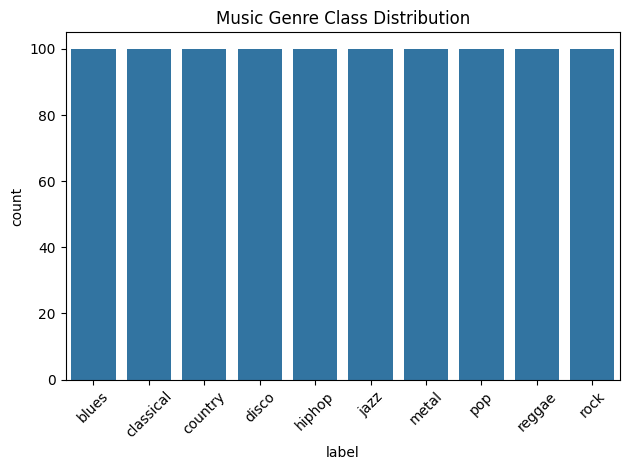

In [6]:
TARGET = "label"

print("Genre counts:")
print(df[TARGET].value_counts())

print("\nGenre percentages:")
print((df[TARGET].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x=TARGET, order=sorted(df[TARGET].unique()))
plt.title("Music Genre Class Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Clean the data

In [7]:
# Remove duplicate rows and rows without a target label
df = df.drop_duplicates()
df = df.dropna(subset=[TARGET]).copy()

# Remove filename and length from predictors
drop_cols = [TARGET, "filename", "length"]
X = df.drop(columns=[c for c in drop_cols if c in df.columns])
y_raw = df[TARGET].astype(str)

# Convert categorical feature columns into numeric columns
X = pd.get_dummies(X, drop_first=True)

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove completely empty feature columns
X = X.dropna(axis=1, how="all")

print("Dataset after cleaning:", df.shape)
print("Feature shape:", X.shape)
print("Missing feature values:", X.isnull().sum().sum())

Dataset after cleaning: (1000, 60)
Feature shape: (1000, 57)
Missing feature values: 0


Explore the data with charts (EDA)

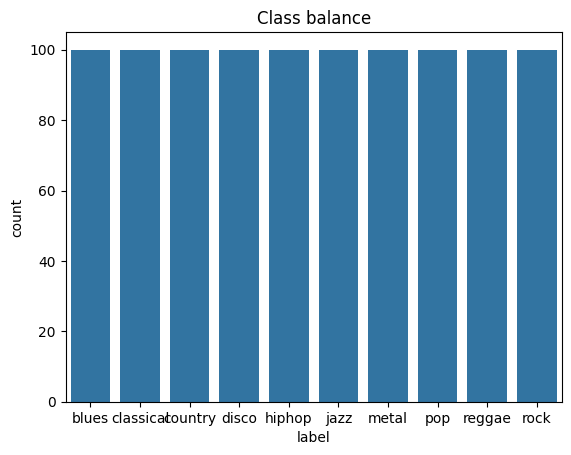

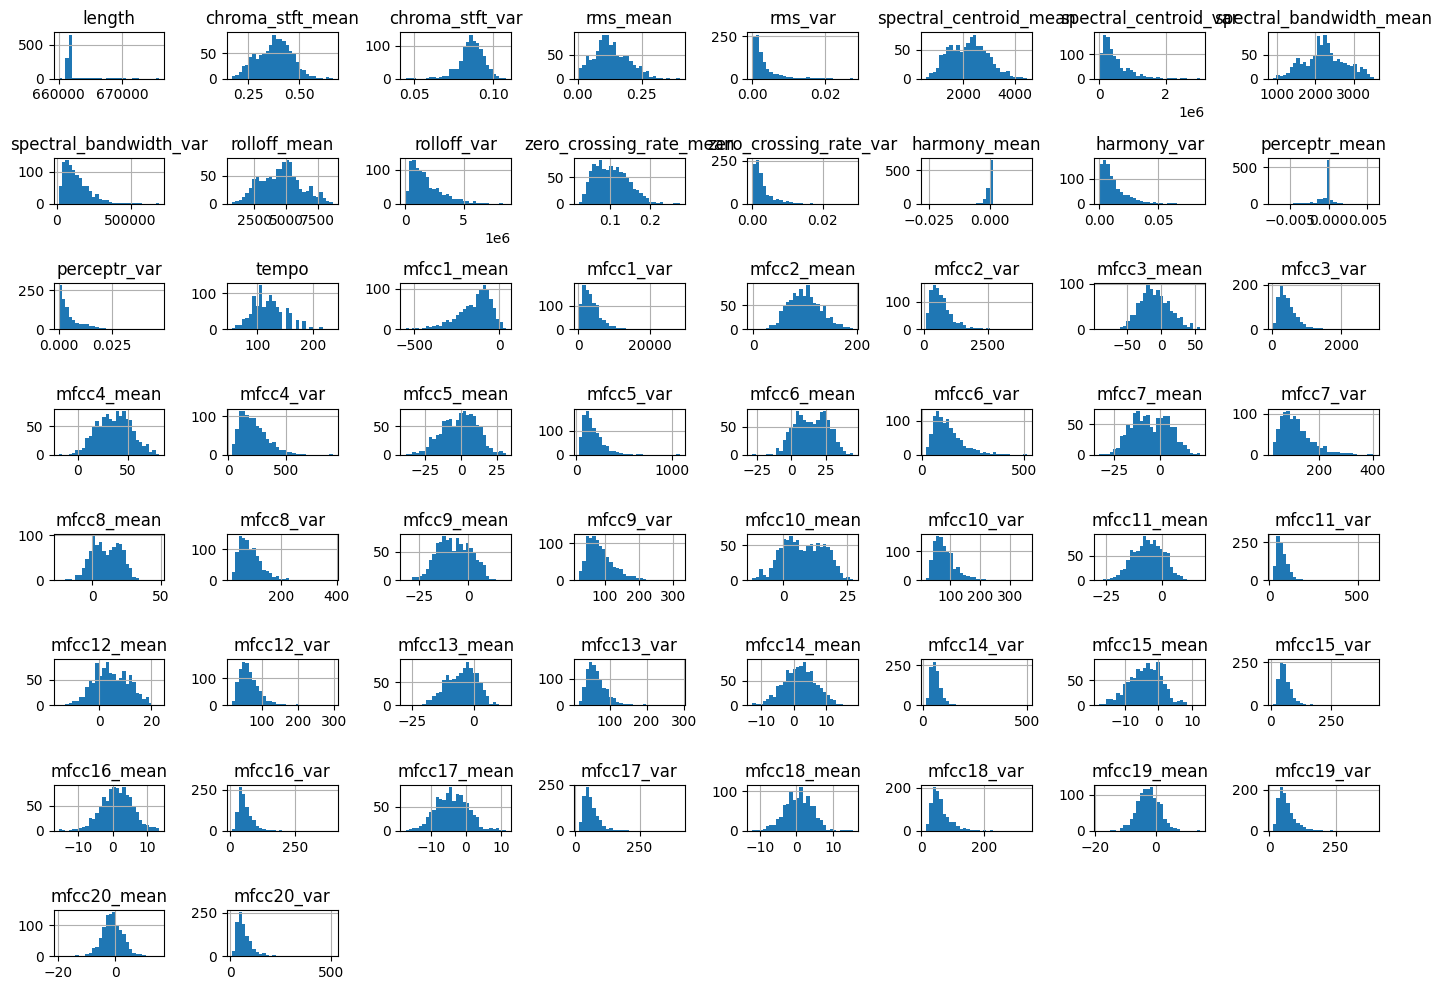

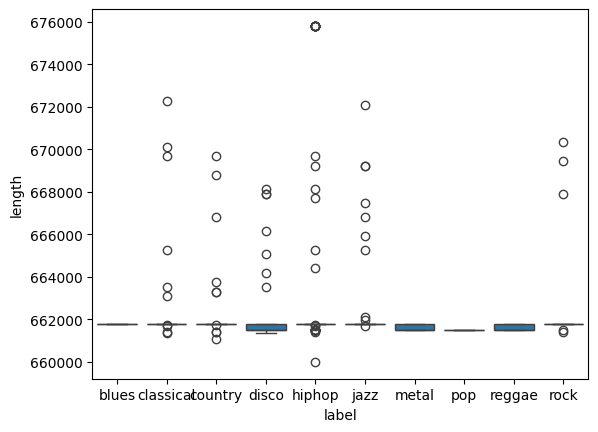

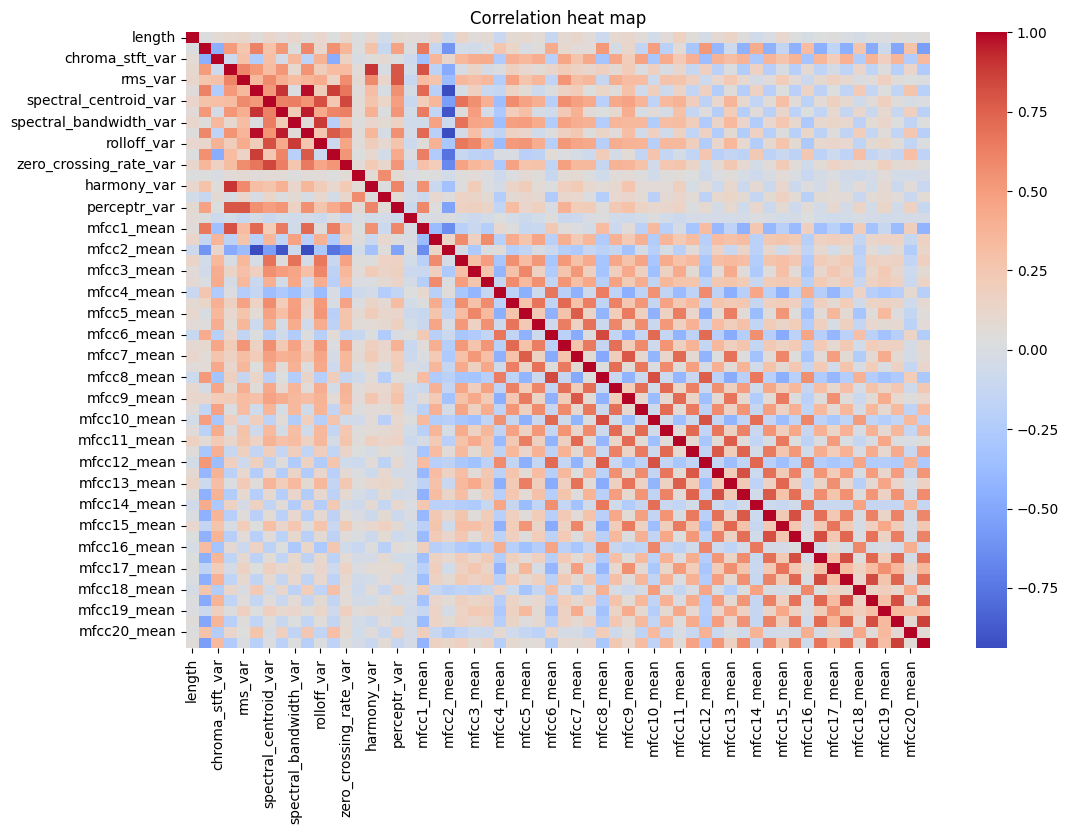

In [9]:
sns.countplot(x=df[TARGET]); plt.title("Class balance"); plt.show()

num_cols = df.select_dtypes(include="number").columns
df[num_cols].hist(figsize=(14, 10), bins=30); plt.tight_layout(); plt.show()

# Box plot of one important numeric column by class (change the column name)
sns.boxplot(x=df[TARGET], y=df[num_cols[0]]); plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df[num_cols].corr(), cmap="coolwarm"); plt.title("Correlation heat map"); plt.show()

Create a new feature, encode and select features

In [10]:
# Create one new feature from the numeric audio features
numeric_cols = X.select_dtypes(include="number").columns.tolist()

if len(numeric_cols) >= 2:
    X["audio_feature_mean"] = X[numeric_cols].mean(axis=1)
elif len(numeric_cols) == 1:
    X["audio_feature_mean"] = X[numeric_cols[0]]
else:
    raise ValueError("No numeric audio features found.")

# Encode target genres
le_y = LabelEncoder()
y = le_y.fit_transform(y_raw)

print("Encoded genres:", list(le_y.classes_))
print("Feature shape:", X.shape)
print("New feature: audio_feature_mean")

Encoded genres: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
Feature shape: (1000, 58)
New feature: audio_feature_mean


Split the data and scale features

In [11]:
# Split: 80% training, 20% testing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train_raw.shape)
print("Testing shape:", X_test_raw.shape)

# Remove columns that are entirely missing in training data
usable_cols = X_train_raw.columns[
    X_train_raw.notna().any()
].tolist()

X_train_raw = X_train_raw[usable_cols].copy()
X_test_raw = X_test_raw[usable_cols].copy()

# Impute missing values using training data only
imputer = SimpleImputer(strategy="median")

X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=usable_cols,
    index=X_train_raw.index
)

X_test_imp = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=usable_cols,
    index=X_test_raw.index
)

# Select up to 15 features using training data only
k = min(15, X_train_imp.shape[1])

selector = SelectKBest(score_func=f_classif, k=k)

X_train_selected = selector.fit_transform(X_train_imp, y_train)
X_test_selected = selector.transform(X_test_imp)

selected_features = X_train_imp.columns[
    selector.get_support()
].tolist()

print("Selected features:")
print(selected_features)

# Standardize features; fit scaler on training data only
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_selected)
X_test = scaler.transform(X_test_selected)

print("Training data scaled:", X_train.shape)
print("Testing data scaled:", X_test.shape)

Training shape: (800, 58)
Testing shape: (200, 58)
Selected features:
['chroma_stft_mean', 'chroma_stft_var', 'rms_mean', 'rms_var', 'spectral_centroid_mean', 'spectral_centroid_var', 'spectral_bandwidth_mean', 'rolloff_mean', 'zero_crossing_rate_mean', 'perceptr_var', 'mfcc1_mean', 'mfcc2_mean', 'mfcc4_mean', 'mfcc6_mean', 'mfcc8_mean']
Training data scaled: (800, 15)
Testing data scaled: (200, 15)


Train the baseline SVM model

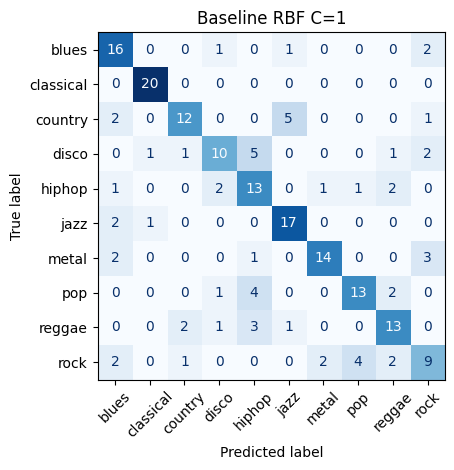

              precision    recall  f1-score   support

       blues       0.64      0.80      0.71        20
   classical       0.91      1.00      0.95        20
     country       0.75      0.60      0.67        20
       disco       0.67      0.50      0.57        20
      hiphop       0.50      0.65      0.57        20
        jazz       0.71      0.85      0.77        20
       metal       0.82      0.70      0.76        20
         pop       0.72      0.65      0.68        20
      reggae       0.65      0.65      0.65        20
        rock       0.53      0.45      0.49        20

    accuracy                           0.69       200
   macro avg       0.69      0.69      0.68       200
weighted avg       0.69      0.69      0.68       200

{'Setting': 'Baseline RBF C=1', 'Accuracy': 0.685, 'Precision': 0.689925430778372, 'Recall': 0.685, 'F1': 0.6816985735177956, 'Specificity': np.float64(0.9649999999999999), 'AUC': 0.9417500000000001}


In [12]:
results = []

def evaluate(name, model, show=False):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(le_y.classes_))
    )

    # Multiclass one-vs-rest specificity
    specificity_values = []

    for i in range(len(cm)):
        tn = cm.sum() - cm[i, :].sum() - cm[:, i].sum() + cm[i, i]
        fp = cm[:, i].sum() - cm[i, i]

        specificity_values.append(
            tn / (tn + fp) if (tn + fp) > 0 else 0
        )

    specificity = np.mean(specificity_values)

    # Multiclass macro AUC
    try:
        probabilities = model.predict_proba(X_test)

        auc = roc_auc_score(
            y_test,
            probabilities,
            labels=np.arange(len(le_y.classes_)),
            multi_class="ovr",
            average="macro"
        )
    except (ValueError, AttributeError):
        auc = np.nan

    row = {
        "Setting": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Specificity": specificity,
        "AUC": auc
    }

    if show:
        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=le_y.classes_
        ).plot(xticks_rotation=45, cmap="Blues", colorbar=False)

        plt.title(name)
        plt.tight_layout()
        plt.show()

        print(classification_report(
            y_test,
            y_pred,
            labels=np.arange(len(le_y.classes_)),
            target_names=[str(c) for c in le_y.classes_],
            zero_division=0
        ))

    print(row)
    return row


# Baseline SVM
baseline_model = SVC(
    kernel="rbf",
    C=1,
    probability=True,
    random_state=42
)

results.append(
    evaluate("Baseline RBF C=1", baseline_model, show=True)
)

Try different SVM settings

In [13]:
# Compare linear and RBF kernels
for kernel in ["linear", "rbf"]:
    model = SVC(
        kernel=kernel,
        C=1,
        probability=True,
        random_state=42
    )

    results.append(
        evaluate(f"Kernel={kernel}", model)
    )

# Compare different C values using RBF kernel
for c in [0.1, 1, 10]:
    model = SVC(
        kernel="rbf",
        C=c,
        probability=True,
        random_state=42
    )

    results.append(
        evaluate(f"RBF C={c}", model)
    )

{'Setting': 'Kernel=linear', 'Accuracy': 0.65, 'Precision': 0.6565960209381263, 'Recall': 0.6499999999999999, 'F1': 0.6483836923310606, 'Specificity': np.float64(0.961111111111111), 'AUC': 0.9318888888888889}
{'Setting': 'Kernel=rbf', 'Accuracy': 0.685, 'Precision': 0.689925430778372, 'Recall': 0.685, 'F1': 0.6816985735177956, 'Specificity': np.float64(0.9649999999999999), 'AUC': 0.9417500000000001}
{'Setting': 'RBF C=0.1', 'Accuracy': 0.525, 'Precision': 0.5049653100218684, 'Recall': 0.525, 'F1': 0.5058351692940851, 'Specificity': np.float64(0.9472222222222222), 'AUC': 0.9172777777777779}
{'Setting': 'RBF C=1', 'Accuracy': 0.685, 'Precision': 0.689925430778372, 'Recall': 0.685, 'F1': 0.6816985735177956, 'Specificity': np.float64(0.9649999999999999), 'AUC': 0.9417500000000001}
{'Setting': 'RBF C=10', 'Accuracy': 0.655, 'Precision': 0.6634495221317472, 'Recall': 0.655, 'F1': 0.6526883243646695, 'Specificity': np.float64(0.9616666666666666), 'AUC': 0.9486388888888888}


Compare settings and select the final model

,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,Baseline RBF C=1,0.685,0.690,0.685,0.682,0.965,0.942
1,Kernel=linear,0.650,0.657,0.650,0.648,0.961,0.932
2,Kernel=rbf,0.685,0.690,0.685,0.682,0.965,0.942
3,RBF C=0.1,0.525,0.505,0.525,0.506,0.947,0.917
4,RBF C=1,0.685,0.690,0.685,0.682,0.965,0.942
5,RBF C=10,0.655,0.663,0.655,0.653,0.962,0.949


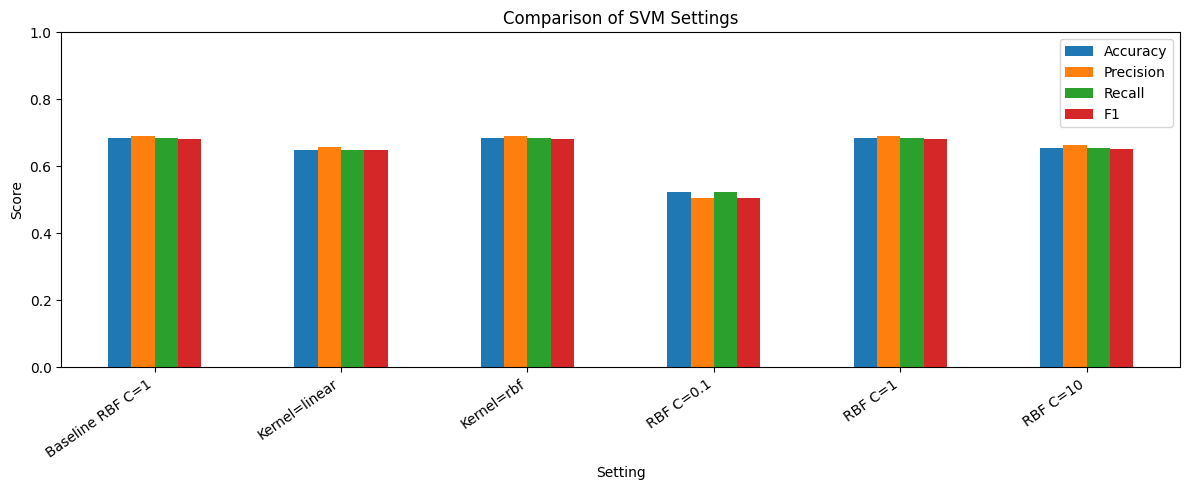

Best setting: Baseline RBF C=1
Accuracy: 0.685
Macro F1: 0.6816985735177956

FINAL MODEL RESULTS
Accuracy: 0.685
Macro Precision: 0.689925430778372
Macro Recall: 0.685
Macro F1: 0.6816985735177956

Classification Report:
              precision    recall  f1-score   support

       blues       0.64      0.80      0.71        20
   classical       0.91      1.00      0.95        20
     country       0.75      0.60      0.67        20
       disco       0.67      0.50      0.57        20
      hiphop       0.50      0.65      0.57        20
        jazz       0.71      0.85      0.77        20
       metal       0.82      0.70      0.76        20
         pop       0.72      0.65      0.68        20
      reggae       0.65      0.65      0.65        20
        rock       0.53      0.45      0.49        20

    accuracy                           0.69       200
   macro avg       0.69      0.69      0.68       200
weighted avg       0.69      0.69      0.68       200



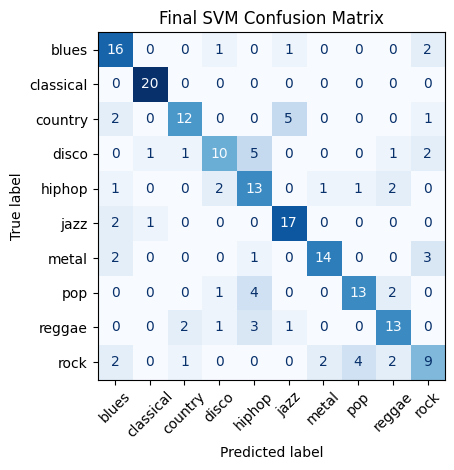

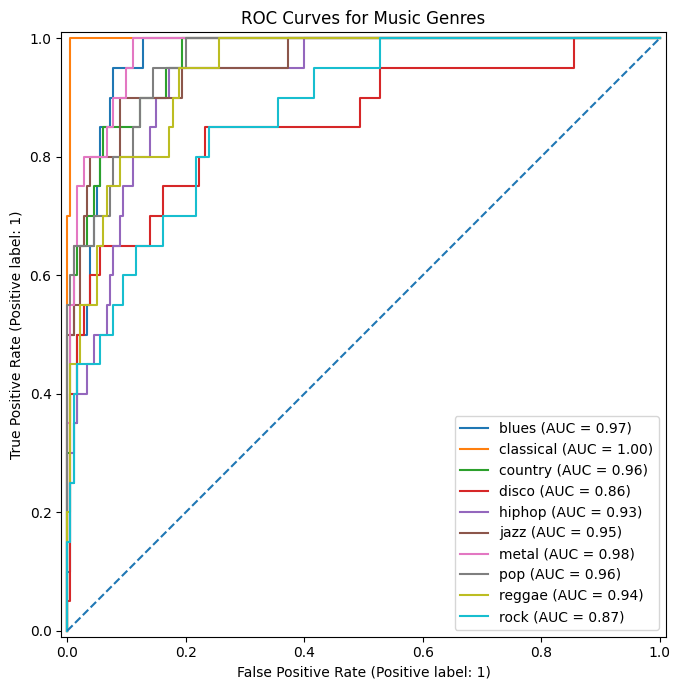

Macro AUC: 0.9417500000000001


In [14]:
# Create comparison table
results_df = pd.DataFrame(results)

# Remove repeated settings from baseline and tuning
results_df = results_df.drop_duplicates(
    subset=["Setting"],
    keep="last"
).reset_index(drop=True)

display(results_df.round(3))

# Compare accuracy, precision, recall and F1
ax = results_df.set_index("Setting")[
    ["Accuracy", "Precision", "Recall", "F1"]
].plot(kind="bar", figsize=(12, 5))

ax.set_title("Comparison of SVM Settings")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Select the best setting by accuracy, then macro F1
ranked = results_df.sort_values(
    ["Accuracy", "F1"],
    ascending=False
).reset_index(drop=True)

best_setting = ranked.iloc[0]["Setting"]

print("Best setting:", best_setting)
print("Accuracy:", ranked.iloc[0]["Accuracy"])
print("Macro F1:", ranked.iloc[0]["F1"])

# Build the selected model
if best_setting == "Kernel=linear":
    final_model = SVC(
        kernel="linear",
        C=1,
        probability=True,
        random_state=42
    )
else:
    best_c = float(best_setting.split("C=")[-1])

    final_model = SVC(
        kernel="rbf",
        C=best_c,
        probability=True,
        random_state=42
    )

# Fit final model and calculate final metrics
final_model.fit(X_train, y_train)

final_pred = final_model.predict(X_test)
final_prob = final_model.predict_proba(X_test)

print("\nFINAL MODEL RESULTS")
print("Accuracy:", accuracy_score(y_test, final_pred))
print(
    "Macro Precision:",
    precision_score(y_test, final_pred, average="macro", zero_division=0)
)
print(
    "Macro Recall:",
    recall_score(y_test, final_pred, average="macro", zero_division=0)
)
print(
    "Macro F1:",
    f1_score(y_test, final_pred, average="macro", zero_division=0)
)

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_pred,
    target_names=[str(c) for c in le_y.classes_],
    zero_division=0
))

# Final confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_pred,
    labels=np.arange(len(le_y.classes_)),
    display_labels=le_y.classes_,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

plt.title("Final SVM Confusion Matrix")
plt.tight_layout()
plt.show()

# Multiclass ROC curve: one-vs-rest
from sklearn.preprocessing import label_binarize

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(len(le_y.classes_))
)

fig, ax = plt.subplots(figsize=(10, 7))

for i, genre in enumerate(le_y.classes_):
    RocCurveDisplay.from_predictions(
        y_test_binary[:, i],
        final_prob[:, i],
        name=str(genre),
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--")
ax.set_title("ROC Curves for Music Genres")
plt.tight_layout()
plt.show()

print(
    "Macro AUC:",
    roc_auc_score(
        y_test,
        final_prob,
        labels=np.arange(len(le_y.classes_)),
        multi_class="ovr",
        average="macro"
    )
)

Predict three examples

In [15]:
# Select three examples
new_inputs = X.iloc[[0, 1, 2]].copy()

# Apply the same imputation
new_imputed = pd.DataFrame(
    imputer.transform(new_inputs[usable_cols]),
    columns=usable_cols,
    index=new_inputs.index
)

# Apply the same feature selection and scaling
new_selected = selector.transform(new_imputed)
new_scaled = scaler.transform(new_selected)

# Predict genres
predictions = final_model.predict(new_scaled)
predicted_genres = le_y.inverse_transform(predictions)

# Display results
prediction_results = pd.DataFrame({
    "Actual Genre": y_raw.loc[new_inputs.index].values,
    "Predicted Genre": predicted_genres,
    "Correct Prediction": (
        y_raw.loc[new_inputs.index].values == predicted_genres
    )
})

display(prediction_results)

,Actual Genre,Predicted Genre,Correct Prediction
0,blues,country,False
1,blues,blues,True
2,blues,rock,False


**Conclusion:**
This project uses SVM to classify music into 10 genres using the GTZAN dataset. Data cleaning, feature selection, scaling, and model tuning are performed to improve classification. Accuracy and macro F1-score are used to evaluate the model. This project helped me understand machine learning, SVM, and model evaluation.